# Digital Image Processing — Lab Task 03
## Image Enhancement and Intensity Transformations

**Name:** Jawahir Ali  
**Roll No:** 2024-SE-34  
**Instructor:** Engr. Fahad Nisar  
**Session:** 2024-28 (SE), Fifth Semester

## 0. Setup, image loading and validation

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from fractions import Fraction
import math

IMAGE_PATH = "image.png"  
MAX_SIDE = 800                   # large images are shrunk so the nested-loop task finishes quickly

original = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
assert original is not None, f"Could not read {IMAGE_PATH}. Check the file name/path."
assert original.ndim == 2 and original.dtype == np.uint8, "Expected an 8-bit grayscale image"
assert original.shape[0] >= 300 and original.shape[1] >= 300, "Image must be at least 300 x 300"

h, w = original.shape
if max(h, w) > MAX_SIDE:
    s = MAX_SIDE / max(h, w)
    original = cv2.resize(original, (int(w * s), int(h * s)), interpolation=cv2.INTER_AREA)

original.setflags(write=False)   # keep the original unchanged: any accidental write raises an error

print("shape :", original.shape)
print("dtype :", original.dtype)
print("min   :", original.min())
print("max   :", original.max())

ModuleNotFoundError: No module named 'cv2'

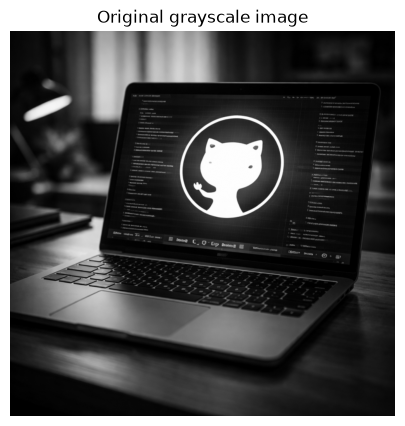

In [ ]:
def to_u8(x):
    """Clip to 0-255 FIRST, then truncate fractions and convert to uint8 (no overflow wrap-around)."""
    return np.clip(x, 0, 255).astype(np.uint8)

def show_pair(img_a, title_a, img_b, title_b, suptitle=None):
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(img_a, cmap="gray", vmin=0, vmax=255); ax[0].set_title(title_a); ax[0].axis("off")
    ax[1].imshow(img_b, cmap="gray", vmin=0, vmax=255); ax[1].set_title(title_b); ax[1].axis("off")
    if suptitle: fig.suptitle(suptitle)
    plt.tight_layout(); plt.show()

def show_row(images, titles, suptitle=None):
    fig, ax = plt.subplots(1, len(images), figsize=(5 * len(images), 5))
    for a, im, t in zip(np.atleast_1d(ax), images, titles):
        a.imshow(im, cmap="gray", vmin=0, vmax=255); a.set_title(t); a.axis("off")
    if suptitle: fig.suptitle(suptitle)
    plt.tight_layout(); plt.show()

def pct(img, lo=None, hi=None):
    n = img.size
    return (100 * np.count_nonzero(img == 0) / n, 100 * np.count_nonzero(img == 255) / n)

plt.figure(figsize=(5, 5))
plt.imshow(original, cmap="gray", vmin=0, vmax=255); plt.title("Original grayscale image"); plt.axis("off"); plt.show()

## 1. Brightness adjustment (β = +40 and −40)

### Dry run 1 — pixels [30, 80, 128, 180, 240]

In [ ]:
P = np.array([30, 80, 128, 180, 240])
for beta in (+40, -40):
    raw = P.astype(np.int32) + beta           # wider type: no wrap-around
    clipped = np.clip(raw, 0, 255)
    final = clipped.astype(np.uint8)
    print(f"beta={beta:+d}  raw={raw.tolist()}  clipped={clipped.tolist()}  uint8={final.tolist()}")

# What would happen WITHOUT widening (overflow demonstration):
print("uint8 wrap-around, 240+40 ->", np.uint8(240) + np.uint8(40), "| 30-40 ->", np.uint8(30) - np.uint8(40))

assert np.clip(P + 40, 0, 255).tolist() == [70, 120, 168, 220, 255]
assert np.clip(P - 40, 0, 255).tolist() == [0, 40, 88, 140, 200]

beta=+40  raw=[70, 120, 168, 220, 280]  clipped=[70, 120, 168, 220, 255]  uint8=[70, 120, 168, 220, 255]
beta=-40  raw=[-10, 40, 88, 140, 200]  clipped=[0, 40, 88, 140, 200]  uint8=[0, 40, 88, 140, 200]
uint8 wrap-around, 240+40 -> 24 | 30-40 -> 246


C:\Users\jawah_czbwkdr\AppData\Local\Temp\ipykernel_24544\3609073329.py:9: RuntimeWarning: overflow encountered in scalar add
  print("uint8 wrap-around, 240+40 ->", np.uint8(240) + np.uint8(40), "| 30-40 ->", np.uint8(30) - np.uint8(40))
C:\Users\jawah_czbwkdr\AppData\Local\Temp\ipykernel_24544\3609073329.py:9: RuntimeWarning: overflow encountered in scalar subtract
  print("uint8 wrap-around, 240+40 ->", np.uint8(240) + np.uint8(40), "| 30-40 ->", np.uint8(30) - np.uint8(40))


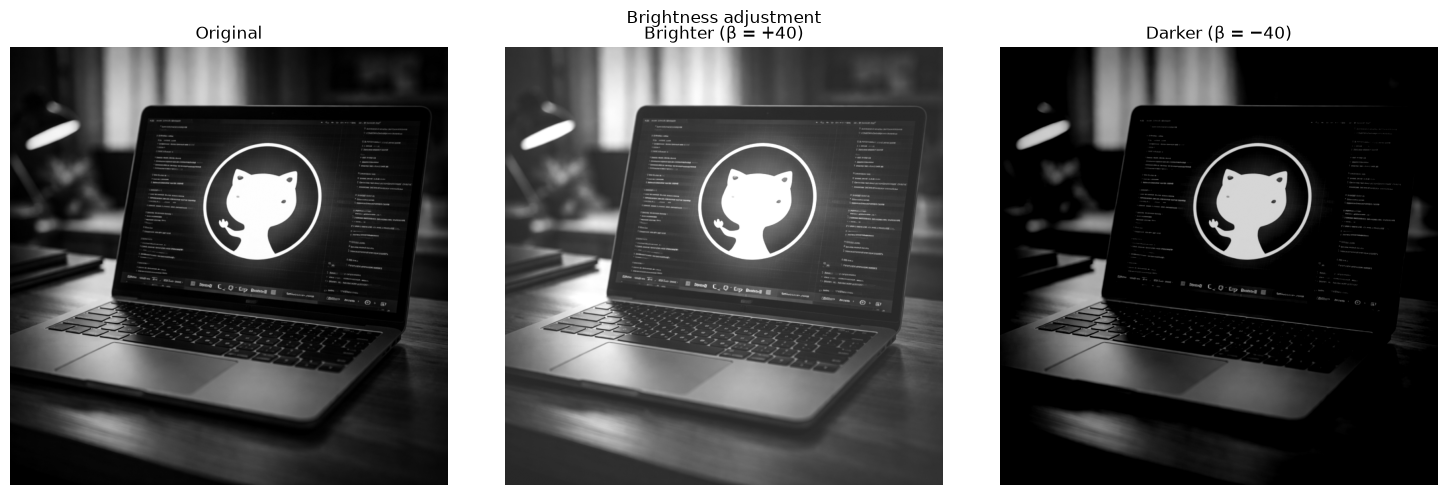

Nested loop result identical to NumPy result: True
Pixels saturated at 255 after +40: 19868 | pixels at 0 after -40: 395169


In [ ]:
bright = to_u8(original.astype(np.int32) + 40)
dark   = to_u8(original.astype(np.int32) - 40)

show_row([original, bright, dark], ["Original", "Brighter (β = +40)", "Darker (β = −40)"], "Brightness adjustment")

# nested-loop version of +40
loop_bright = np.zeros_like(original)
rows, cols = original.shape
for i in range(rows):
    for j in range(cols):
        v = int(original[i, j]) + 40
        if v > 255: v = 255
        if v < 0: v = 0
        loop_bright[i, j] = v

print("Nested loop result identical to NumPy result:", np.array_equal(loop_bright, bright))
assert np.array_equal(loop_bright, bright)
print("Pixels saturated at 255 after +40:", np.count_nonzero(bright == 255), "| pixels at 0 after -40:", np.count_nonzero(dark == 0))

**Observation:** adding +40 shifts every intensity up, pixels that were ≥ 215 pile up at 255 (highlight detail lost); −40 shifts down and pixels ≤ 40 become 0 (shadow detail lost). Brightness changes the *position* of the histogram, not its spread.

## 2. Linear contrast from zero: s = αr + β, α = 1.5, β = 0

### Dry run 2 — pixels [30, 80, 128, 180, 240]

In [ ]:
P = np.array([30, 80, 128, 180, 240])
raw = 1.5 * P
final = to_u8(raw)
for r, a, b in zip(P, raw, final):
    print(f"r={r:3d}  1.5r={a:6.1f}  clipped+truncated={b:3d}  saturated={a > 255}")
assert final.tolist() == [45, 120, 192, 255, 255]

r= 30  1.5r=  45.0  clipped+truncated= 45  saturated=False
r= 80  1.5r= 120.0  clipped+truncated=120  saturated=False
r=128  1.5r= 192.0  clipped+truncated=192  saturated=False
r=180  1.5r= 270.0  clipped+truncated=255  saturated=True
r=240  1.5r= 360.0  clipped+truncated=255  saturated=True


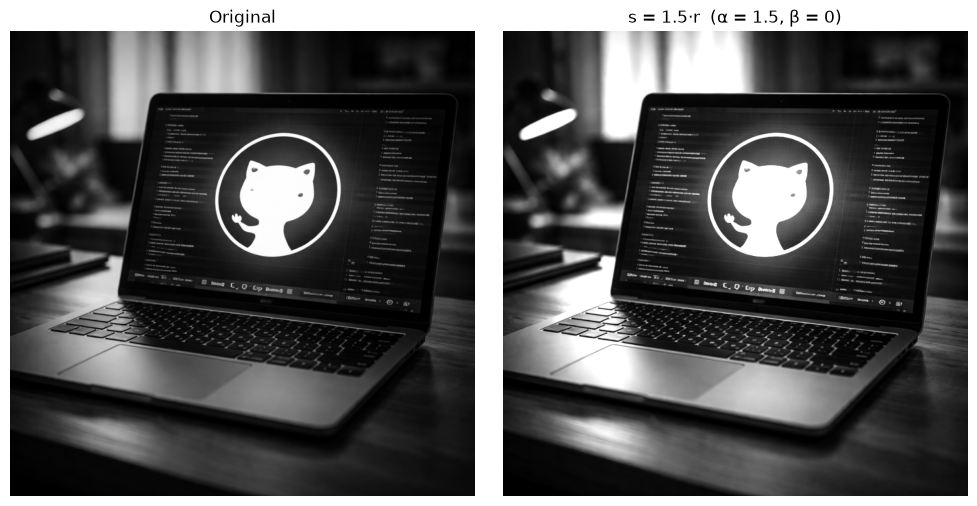

Mean brightness  original: 52.01  linear: 72.78
Saturated (255) pixels  original: 0.00%   linear: 7.71%


In [ ]:
lin = to_u8(1.5 * original.astype(np.float64) + 0)
show_pair(original, "Original", lin, "s = 1.5·r  (α = 1.5, β = 0)")
print("Mean brightness  original:", round(original.mean(), 2), " linear:", round(lin.mean(), 2))
print("Saturated (255) pixels  original: %.2f%%   linear: %.2f%%" % (pct(original)[1], pct(lin)[1]))

**Observation:** the image becomes brighter overall (not just higher contrast) and all pixels with r ≥ 170 saturate at 255, so highlight detail is clipped.

## 3. Contrast centered at 128: s = (r − 128)α + 128, α = 1.5 and 0.5

### Dry run 3 — pixels [30, 80, 128, 180, 240]

In [ ]:
P = np.array([30, 80, 128, 180, 240])
for a in (1.5, 0.5):
    d = P - 128
    m = d * a
    raw = m + 128
    final = to_u8(raw)
    print(f"alpha={a}: r-128={d.tolist()}  *alpha={m.tolist()}  +128={raw.tolist()}  final={final.tolist()}")
assert to_u8((P - 128) * 1.5 + 128).tolist() == [0, 56, 128, 206, 255]
assert to_u8((P - 128) * 0.5 + 128).tolist() == [79, 104, 128, 154, 184]
print("r = 128 maps to 128 for any alpha (the pivot).")

alpha=1.5: r-128=[-98, -48, 0, 52, 112]  *alpha=[-147.0, -72.0, 0.0, 78.0, 168.0]  +128=[-19.0, 56.0, 128.0, 206.0, 296.0]  final=[0, 56, 128, 206, 255]
alpha=0.5: r-128=[-98, -48, 0, 52, 112]  *alpha=[-49.0, -24.0, 0.0, 26.0, 56.0]  +128=[79.0, 104.0, 128.0, 154.0, 184.0]  final=[79, 104, 128, 154, 184]
r = 128 maps to 128 for any alpha (the pivot).


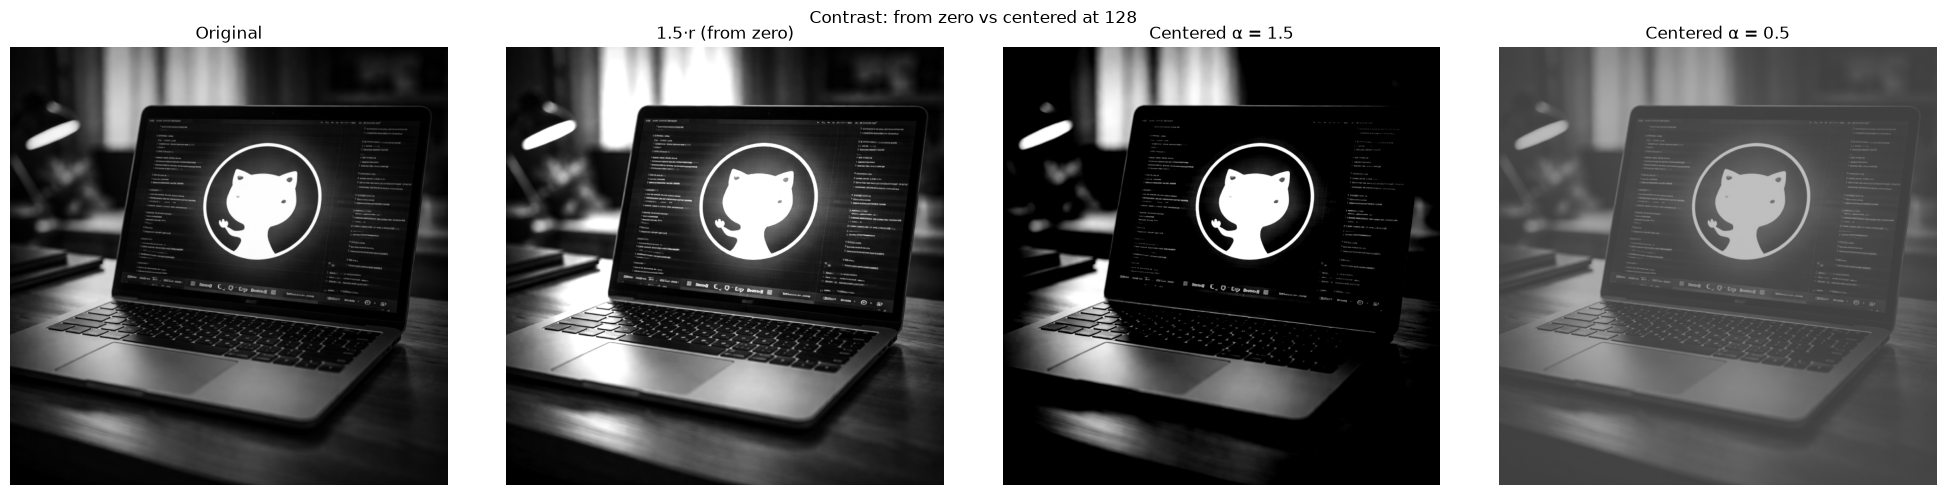

original      mean= 52.01 std= 60.47 pct@0= 2.52% pct@255= 0.00%
1.5r          mean= 72.78 std= 77.05 pct@0= 2.52% pct@255= 7.71%
centered 1.5  mean= 36.81 std= 70.33 pct@0=63.75% pct@255= 3.24%
centered 0.5  mean= 89.76 std= 30.24 pct@0= 0.00% pct@255= 0.00%


In [ ]:
f = original.astype(np.float64)
c_hi = to_u8((f - 128) * 1.5 + 128)
c_lo = to_u8((f - 128) * 0.5 + 128)
show_row([original, lin, c_hi, c_lo],
         ["Original", "1.5·r (from zero)", "Centered α = 1.5", "Centered α = 0.5"],
         "Contrast: from zero vs centered at 128")
for name, im in [("original", original), ("1.5r", lin), ("centered 1.5", c_hi), ("centered 0.5", c_lo)]:
    print(f"{name:13s} mean={im.mean():6.2f} std={im.std():6.2f} pct@0={pct(im)[0]:5.2f}% pct@255={pct(im)[1]:5.2f}%")

**Observation:** α = 1.5 centered at 128 increases contrast on both sides of mid-gray (some shadows clip to 0 and highlights to 255), while α = 0.5 compresses values toward 128 and gives a flat, washed-out look. Unlike 1.5·r, the centered version does not raise the overall brightness.

## 4. Image negative: s = 255 − r

### Dry run 4 — pixels [30, 80, 128, 180, 240]

In [ ]:
P = np.array([30, 80, 128, 180, 240])
neg = 255 - P
neg2 = 255 - neg
print("negative      :", neg.tolist())
print("negative twice:", neg2.tolist(), "| equals original:", np.array_equal(neg2, P))
assert neg.tolist() == [225, 175, 127, 75, 15] and np.array_equal(neg2, P)

negative      : [225, 175, 127, 75, 15]
negative twice: [30, 80, 128, 180, 240] | equals original: True


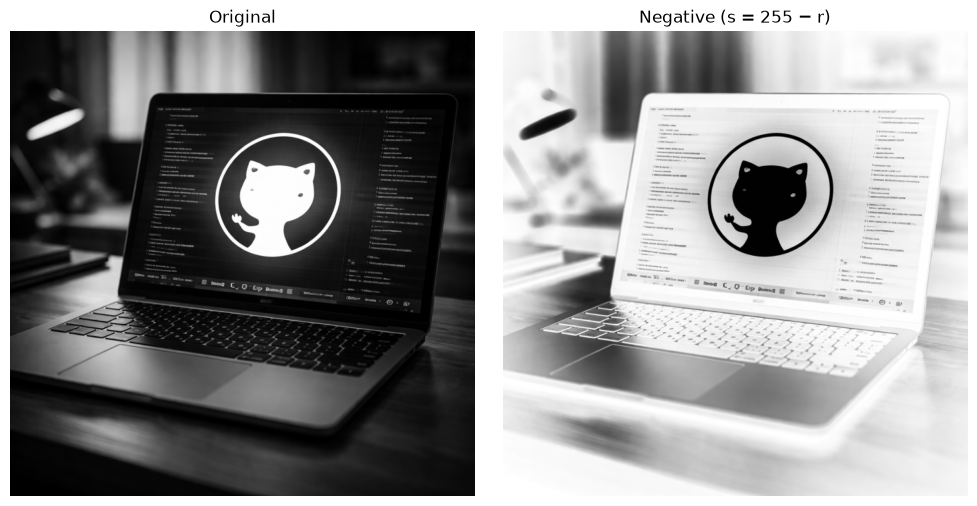

Negative of negative equals original: True


In [ ]:
negative = to_u8(255 - original.astype(np.int32))
show_pair(original, "Original", negative, "Negative (s = 255 − r)")
print("Negative of negative equals original:", np.array_equal(to_u8(255 - negative.astype(np.int32)), original))

**Observation / use case:** the negative can help inspection when the interesting detail is dark on a dark background, for example faint tissue structures in an X-ray or mammogram, because it turns subtle dark detail into bright detail on a dark background, which the eye distinguishes more easily. The transform is its own inverse and loses nothing.

## 5. Gamma correction: s = 255 (r/255)^γ, γ = 0.5 and 2.0

### Dry run 5 — pixels [0, 64, 128, 192, 255]

In [ ]:
G = np.array([0, 64, 128, 192, 255])
for g in (0.5, 2.0):
    n = G / 255.0
    pw = n ** g
    sc = 255 * pw
    fin = to_u8(sc)      # full precision kept, truncate only at the end
    print(f"gamma={g}")
    for r, a, b, c, d in zip(G, n, pw, sc, fin):
        print(f"   r={r:3d} norm={a:.6f} power={b:.6f} x255={c:9.4f} final={d}")
assert to_u8(255 * (G / 255.0) ** 0.5).tolist() == [0, 127, 180, 221, 255]
assert to_u8(255 * (G / 255.0) ** 2.0).tolist() == [0, 16, 64, 144, 255]

gamma=0.5
   r=  0 norm=0.000000 power=0.000000 x255=   0.0000 final=0
   r= 64 norm=0.250980 power=0.500979 x255= 127.7498 final=127
   r=128 norm=0.501961 power=0.708492 x255= 180.6654 final=180
   r=192 norm=0.752941 power=0.867722 x255= 221.2691 final=221
   r=255 norm=1.000000 power=1.000000 x255= 255.0000 final=255
gamma=2.0
   r=  0 norm=0.000000 power=0.000000 x255=   0.0000 final=0
   r= 64 norm=0.250980 power=0.062991 x255=  16.0627 final=16
   r=128 norm=0.501961 power=0.251965 x255=  64.2510 final=64
   r=192 norm=0.752941 power=0.566920 x255= 144.5647 final=144
   r=255 norm=1.000000 power=1.000000 x255= 255.0000 final=255


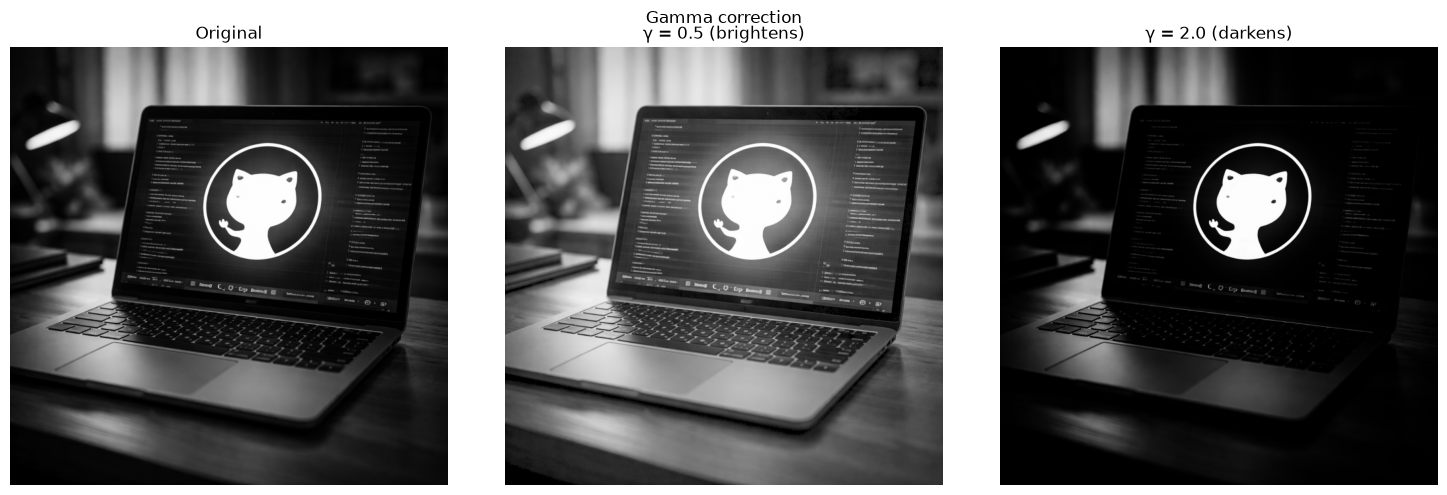

gamma=0.5: 0 -> 0, 255 -> 255
gamma=2.0: 0 -> 0, 255 -> 255
Mean of dark region (r<64)  original: 22.06  gamma0.5: 68.02  gamma2.0: 2.60


In [ ]:
def gamma_correct(img, g):
    return to_u8(255.0 * (img.astype(np.float64) / 255.0) ** g)

g_half = gamma_correct(original, 0.5)
g_two  = gamma_correct(original, 2.0)
show_row([original, g_half, g_two], ["Original", "γ = 0.5 (brightens)", "γ = 2.0 (darkens)"], "Gamma correction")

# 0 and 255 stay fixed
for g in (0.5, 2.0):
    print(f"gamma={g}: 0 -> {gamma_correct(np.array([0], np.uint8), g)[0]}, 255 -> {gamma_correct(np.array([255], np.uint8), g)[0]}")

dark_mask = original < 64
print("Mean of dark region (r<64)  original: %.2f  gamma0.5: %.2f  gamma2.0: %.2f" %
      (original[dark_mask].mean(), g_half[dark_mask].mean(), g_two[dark_mask].mean()))

**Observation:** with this convention (s = 255·(r/255)^γ) γ < 1 brightens and expands dark regions, γ > 1 darkens the image and compresses dark regions. 0 and 255 never change. Differences from a rounded slide example come from rounding the normalized value or the final value early; here full precision is kept and the final value is truncated.

## 6. Grayscale histogram

### Dry run 6 — A = [[0, 50, 50, 100], [100, 150, 200, 255]]

In [ ]:
A = np.array([[0, 50, 50, 100], [100, 150, 200, 255]])
vals, counts = np.unique(A, return_counts=True)
N = A.size
for v, c in zip(vals, counts):
    print(f"intensity {v:3d}: frequency {c}, probability {c}/{N} = {c / N:.4f}")
print("total pixels:", N, "| sum of frequencies:", counts.sum(), "| sum of probabilities:", (counts / N).sum())

B = np.array([[255, 200, 150, 100], [100, 50, 50, 0]])   # same pixels, different positions
print("Different arrangement has the same histogram:",
      np.array_equal(np.bincount(A.ravel(), minlength=256), np.bincount(B.ravel(), minlength=256)))

intensity   0: frequency 1, probability 1/8 = 0.1250
intensity  50: frequency 2, probability 2/8 = 0.2500
intensity 100: frequency 2, probability 2/8 = 0.2500
intensity 150: frequency 1, probability 1/8 = 0.1250
intensity 200: frequency 1, probability 1/8 = 0.1250
intensity 255: frequency 1, probability 1/8 = 0.1250
total pixels: 8 | sum of frequencies: 8 | sum of probabilities: 1.0
Different arrangement has the same histogram: True


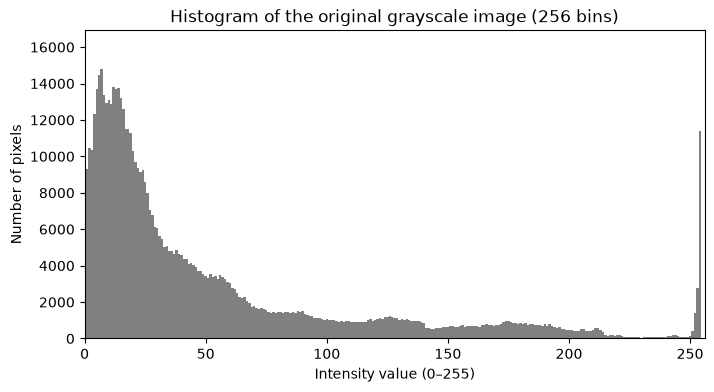

sum of histogram = 640000 = number of pixels 640000


In [ ]:
hist = cv2.calcHist([original], [0], None, [256], [0, 256]).ravel()
plt.figure(figsize=(8, 4))
plt.bar(np.arange(256), hist, width=1.0, color="gray")
plt.xlim(0, 256)
plt.title("Histogram of the original grayscale image (256 bins)")
plt.xlabel("Intensity value (0–255)"); plt.ylabel("Number of pixels")
plt.show()
print("sum of histogram =", int(hist.sum()), "= number of pixels", original.size)

**Interpretation (2 sentences):** *Write this after looking at YOUR histogram.* Example wording: "The histogram of my image is concentrated mainly between about ___ and ___, with a peak near ___, so the image is (dark / bright / low-contrast / well spread). Very few pixels are near 0 or 255, which means (little clipping / limited use of the full range)."

## 7. Global histogram equalization (cv2.equalizeHist)

### Dry run 7 — pixels [50, 50, 100, 150]

In [ ]:
X = [50, 50, 100, 150]
N = len(X)
levels = sorted(set(X))
cum = 0
cdfs = {}
for v in levels:
    cum += X.count(v)
    cdfs[v] = Fraction(cum, N)
    print(f"r={v}: freq={X.count(v)} cumulative={cum} CDF={cdfs[v]} = {float(cdfs[v])}")
cdfmin = min(cdfs.values())
print("CDFmin =", cdfmin)

def round_half_up(fr):          # exact arithmetic, .5 always goes up
    return math.floor(fr + Fraction(1, 2))

m1 = {v: round_half_up(255 * c) for v, c in cdfs.items()}
m2 = {v: round_half_up(255 * (c - cdfmin) / (1 - cdfmin)) for v, c in cdfs.items()}
out1 = [m1[v] for v in X]
out2 = [m2[v] for v in X]
print("Method 1: 255*CDF                      ->", out1)
print("Method 2: 255*(CDF-CDFmin)/(1-CDFmin)  ->", out2)

cv_out = cv2.equalizeHist(np.array([X], dtype=np.uint8))[0].tolist()
print("cv2.equalizeHist                       ->", cv_out, "| matches method 2:", cv_out == out2)
assert out1 == [128, 128, 191, 255] and out2 == [0, 0, 128, 255] and cv_out == out2

r=50: freq=2 cumulative=2 CDF=1/2 = 0.5
r=100: freq=1 cumulative=3 CDF=3/4 = 0.75
r=150: freq=1 cumulative=4 CDF=1 = 1.0
CDFmin = 1/2
Method 1: 255*CDF                      -> [128, 128, 191, 255]
Method 2: 255*(CDF-CDFmin)/(1-CDFmin)  -> [0, 0, 128, 255]
cv2.equalizeHist                       -> [0, 0, 128, 255] | matches method 2: True


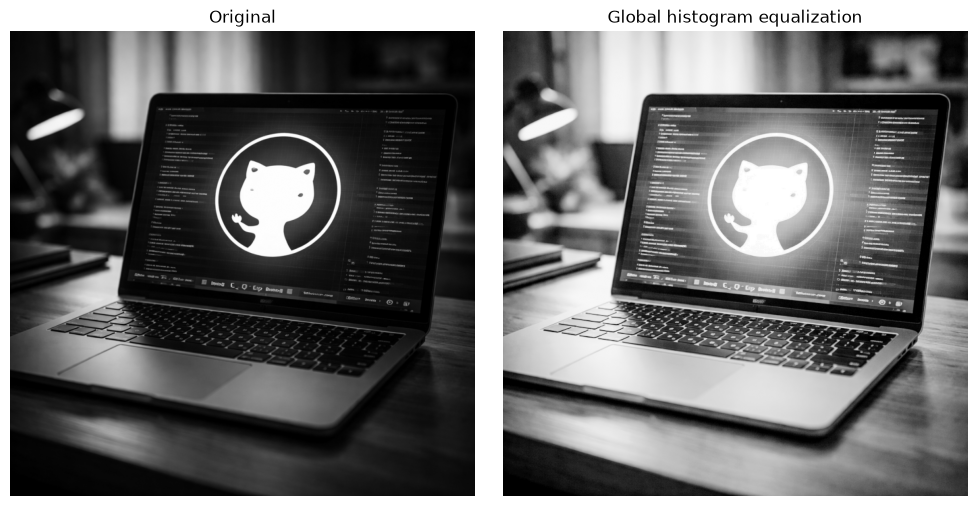

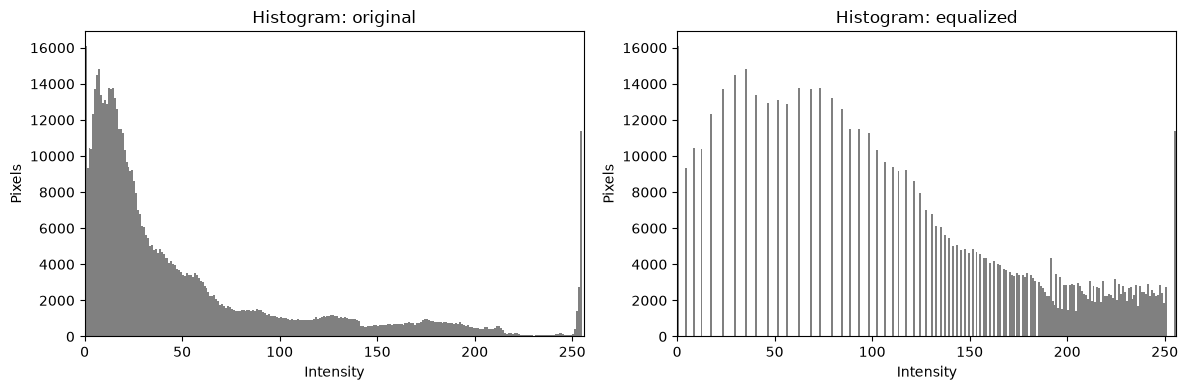

std original: 60.47   std equalized: 74.58


In [ ]:
equalized = cv2.equalizeHist(original)
show_pair(original, "Original", equalized, "Global histogram equalization")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(original.ravel(), bins=256, range=(0, 256), color="gray"); ax[0].set_title("Histogram: original")
ax[1].hist(equalized.ravel(), bins=256, range=(0, 256), color="gray"); ax[1].set_title("Histogram: equalized")
for a in ax: a.set_xlabel("Intensity"); a.set_ylabel("Pixels"); a.set_xlim(0, 256)
plt.tight_layout(); plt.show()
print("std original: %.2f   std equalized: %.2f" % (original.std(), equalized.std()))

**Discussion:** *Complete after viewing YOUR result.* Equalization spreads intensities over the whole 0–255 range, which usually improves visibility of detail in dark or low-contrast areas; but it is global, so flat regions can get over-stretched, noise (e.g., in the sky or other smooth areas) can become stronger, and bright areas may look unnatural. State clearly whether detail improved in your image and whether noise became more visible.

## 8. CLAHE (cv2.createCLAHE, clipLimit = 2.0, tileGridSize = (8, 8))

### Dry run 8 — histogram [6, 2, 0, 0], absolute bin cap 4

In [ ]:
H = [6, 2, 0, 0]
cap = 4
clipped = [min(h, cap) for h in H]
excess = sum(H) - sum(clipped)
add = Fraction(excess, len(H))
newH = [Fraction(c) + add for c in clipped]
print("clipped          :", clipped, "| excess:", excess)
print("add per bin      :", add)
print("new histogram    :", [float(x) for x in newH], "| total:", float(sum(newH)))
cs = np.cumsum([float(x) for x in newH])
cdf = cs / cs[-1]
print("cumulative       :", cs.tolist())
print("new CDF          :", cdf.tolist())
print("255*CDF          :", (255 * cdf).round(2).tolist())
assert cdf.tolist() == [0.5625, 0.875, 0.9375, 1.0]

clipped          : [4, 2, 0, 0] | excess: 2
add per bin      : 1/2
new histogram    : [4.5, 2.5, 0.5, 0.5] | total: 8.0
cumulative       : [4.5, 7.0, 7.5, 8.0]
new CDF          : [0.5625, 0.875, 0.9375, 1.0]
255*CDF          : [143.44, 223.12, 239.06, 255.0]


Neighbouring tiles need interpolation because each tile has its own mapping; using one tile's mapping up to the border and the next tile's mapping after it creates visible block seams. OpenCV blends the mappings of the nearest tile centres bilinearly.  
This simplified model differs from OpenCV's integer redistribution, and the absolute cap of 4 is not the same as OpenCV's `clipLimit` parameter.

Image (800, 800) -> each tile is about 100 x 100 pixels


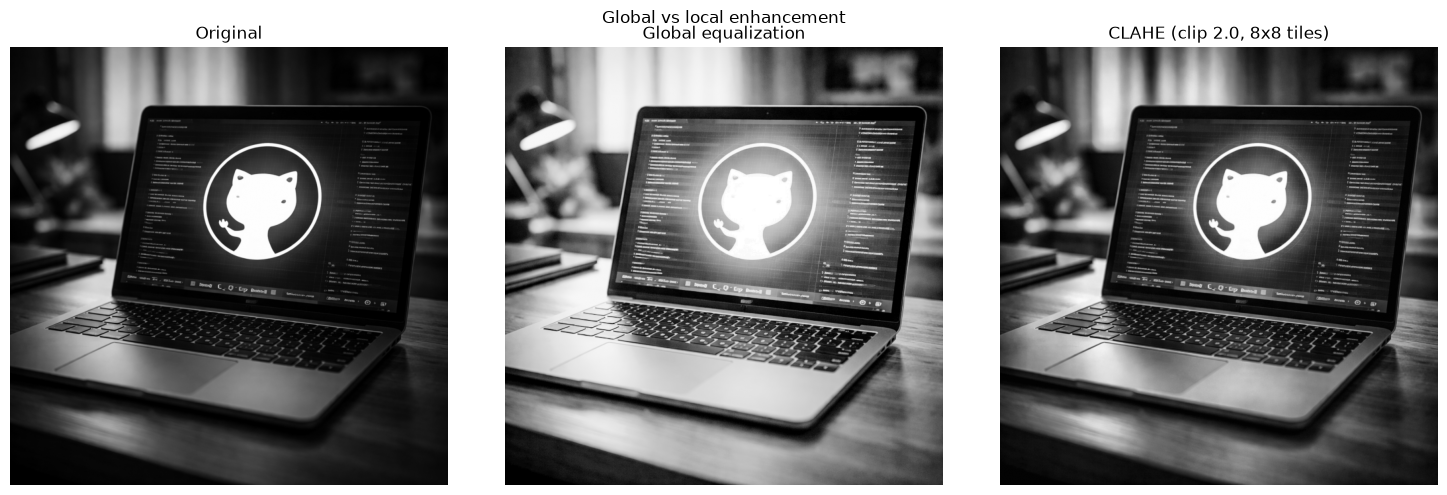

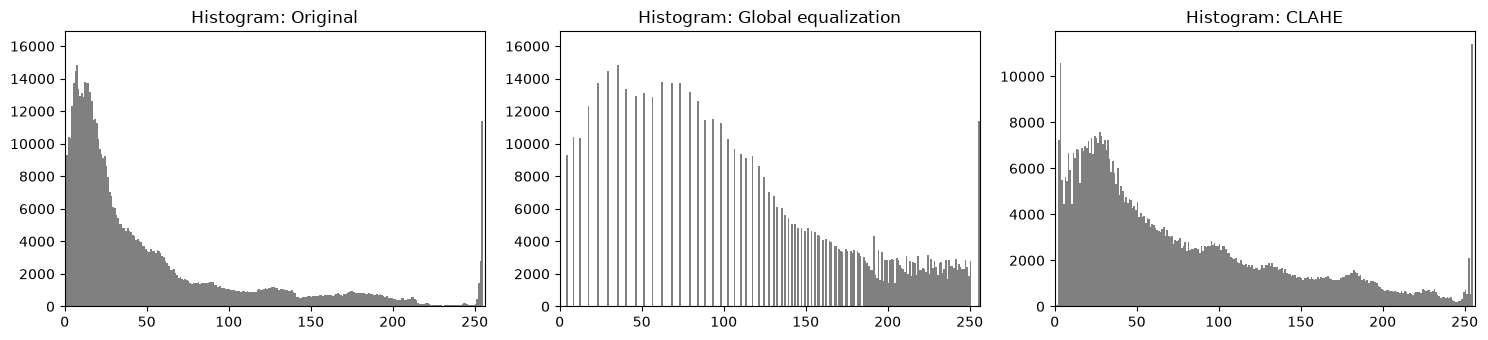

In [ ]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))   # (8, 8) = 8 x 8 TILES, not pixels per tile
clahe_img = clahe.apply(original)
tile_h, tile_w = original.shape[0] // 8, original.shape[1] // 8
print(f"Image {original.shape} -> each tile is about {tile_h} x {tile_w} pixels")

show_row([original, equalized, clahe_img], ["Original", "Global equalization", "CLAHE (clip 2.0, 8x8 tiles)"], "Global vs local enhancement")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, im, t in zip(ax, [original, equalized, clahe_img], ["Original", "Global equalization", "CLAHE"]):
    a.hist(im.ravel(), bins=256, range=(0, 256), color="gray"); a.set_title("Histogram: " + t); a.set_xlim(0, 256)
plt.tight_layout(); plt.show()

**Comparison:** *Complete for YOUR image.* CLAHE equalizes each of the 8 × 8 tiles separately with a limit on contrast amplification, so it brings out local detail in unevenly lit parts (e.g., shadow regions) without the washed-out/over-stretched look global equalization can produce. Note (8, 8) is the number of tiles, not the tile size in pixels.

## 9. Fixed binary thresholding (T = 127)

### Dry run 9 — pixels [0, 80, 127, 128, 180, 255]

In [ ]:
T9 = np.array([0, 80, 127, 128, 180, 255])
for T in (127, 180):
    out = np.where(T9 > T, 255, 0)
    print(f"T={T}: {out.tolist()}  white pixels: {np.count_nonzero(out == 255)}")
assert np.where(T9 > 127, 255, 0).tolist() == [0, 0, 0, 255, 255, 255]
assert np.where(T9 > 180, 255, 0).tolist() == [0, 0, 0, 0, 0, 255]

T=127: [0, 0, 0, 255, 255, 255]  white pixels: 3
T=180: [0, 0, 0, 0, 0, 255]  white pixels: 1


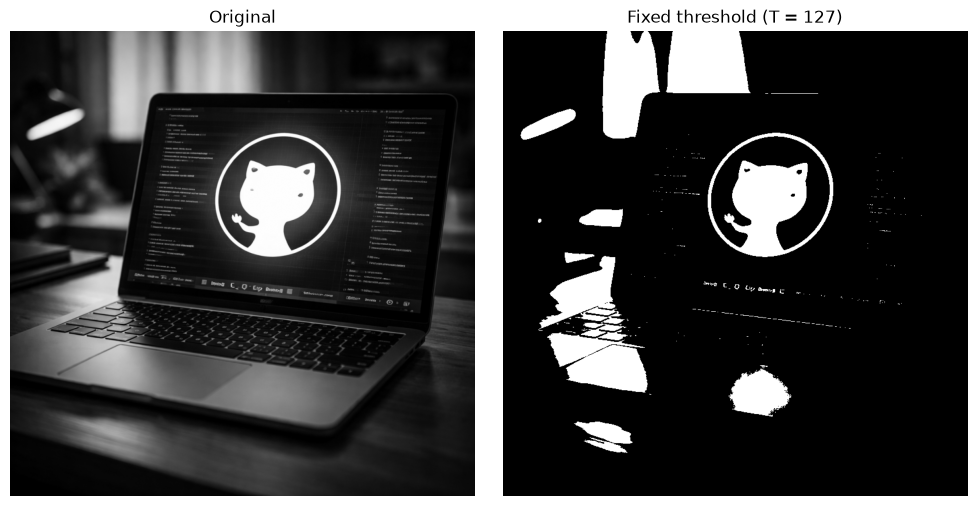

Unique values in binary image: [0, 255]
White pixels: 12.71%


In [ ]:
T_fixed, binary = cv2.threshold(original, 127, 255, cv2.THRESH_BINARY)
show_pair(original, "Original", binary, f"Fixed threshold (T = {int(T_fixed)})")
print("Unique values in binary image:", np.unique(binary).tolist())
print("White pixels: %.2f%%" % (100 * np.count_nonzero(binary == 255) / binary.size))

## 10. Otsu thresholding

### Dry run 10 — pixels [0, 1, 4, 5] (no rescaling)

In [ ]:
O = np.array([0, 1, 4, 5])
N = len(O)
best_T, best_s = None, -1
for T in range(0, 5):
    c0 = O[O <= T]; c1 = O[O > T]
    w0 = Fraction(len(c0), N); w1 = Fraction(len(c1), N)
    m0 = Fraction(int(c0.sum()), len(c0)); m1 = Fraction(int(c1.sum()), len(c1))
    s = w0 * w1 * (m0 - m1) ** 2
    print(f"T={T}: class0={c0.tolist()} class1={c1.tolist()} w0={float(w0):.2f} w1={float(w1):.2f} "
          f"mu0={float(m0):.4f} mu1={float(m1):.4f}  w0*w1*(mu0-mu1)^2={float(s):.4f}")
    if s > best_s:                      # strict '>' keeps the SMALLEST T among ties
        best_s, best_T = s, T
print("Chosen T (smallest among tied maxima):", best_T)
pred = np.where(O > best_T, 255, 0)
print("Predicted mask:", pred.tolist())

t_cv, m_cv = cv2.threshold(O.astype(np.uint8).reshape(1, -1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("OpenCV threshold:", t_cv, "| OpenCV mask:", m_cv.ravel().tolist(), "| matches prediction:", np.array_equal(m_cv.ravel(), pred))
assert best_T == 1 and np.array_equal(m_cv.ravel(), pred)

T=0: class0=[0] class1=[1, 4, 5] w0=0.25 w1=0.75 mu0=0.0000 mu1=3.3333  w0*w1*(mu0-mu1)^2=2.0833
T=1: class0=[0, 1] class1=[4, 5] w0=0.50 w1=0.50 mu0=0.5000 mu1=4.5000  w0*w1*(mu0-mu1)^2=4.0000
T=2: class0=[0, 1] class1=[4, 5] w0=0.50 w1=0.50 mu0=0.5000 mu1=4.5000  w0*w1*(mu0-mu1)^2=4.0000
T=3: class0=[0, 1] class1=[4, 5] w0=0.50 w1=0.50 mu0=0.5000 mu1=4.5000  w0*w1*(mu0-mu1)^2=4.0000
T=4: class0=[0, 1, 4] class1=[5] w0=0.75 w1=0.25 mu0=1.6667 mu1=5.0000  w0*w1*(mu0-mu1)^2=2.0833
Chosen T (smallest among tied maxima): 1
Predicted mask: [0, 0, 255, 255]
OpenCV threshold: 1.0 | OpenCV mask: [0, 0, 255, 255] | matches prediction: True


Otsu threshold returned by OpenCV: 97.0


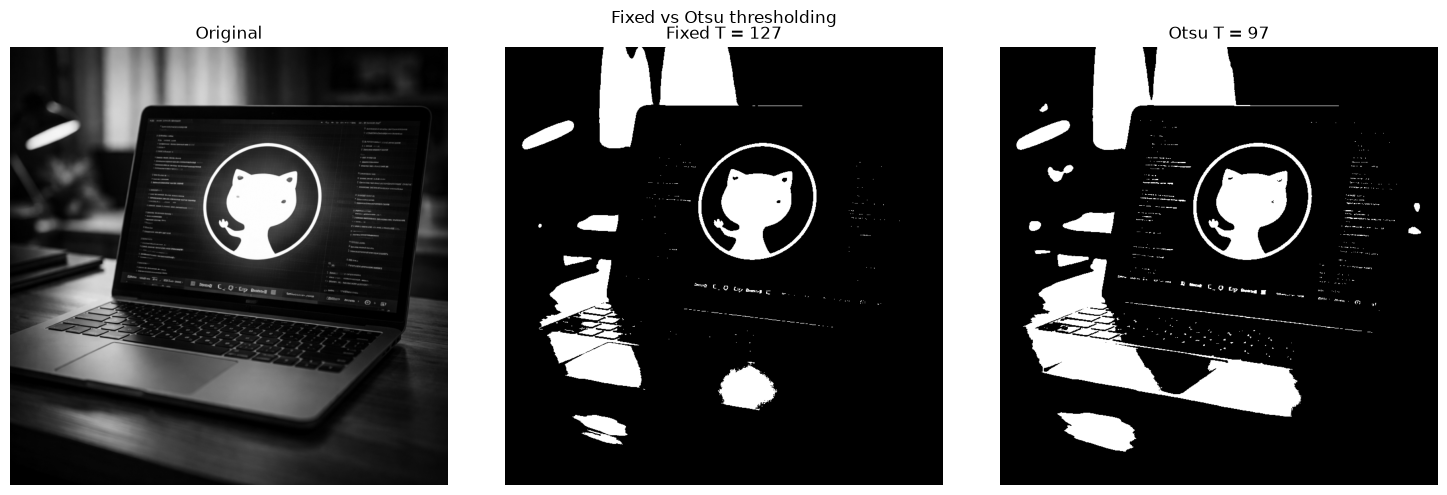

Pixels where fixed and Otsu masks disagree: 30271 (4.73%)
White pixels  fixed: 12.71%   Otsu: 17.44%


In [ ]:
T_otsu, otsu = cv2.threshold(original, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Otsu threshold returned by OpenCV:", T_otsu)

show_row([original, binary, otsu], ["Original", "Fixed T = 127", f"Otsu T = {T_otsu:.0f}"], "Fixed vs Otsu thresholding")

diff = np.count_nonzero(binary != otsu)
print("Pixels where fixed and Otsu masks disagree: %d (%.2f%%)" % (diff, 100 * diff / binary.size))
print("White pixels  fixed: %.2f%%   Otsu: %.2f%%" % (100 * np.mean(binary == 255), 100 * np.mean(otsu == 255)))

**Comparison:** *Complete for YOUR image.* Otsu picks T automatically by maximising between-class variance, so it adapts to the image's histogram instead of using an arbitrary 127. If the returned T is close to 127 the masks are similar; if not, the masks differ mostly in the pixels whose value lies between the two thresholds.

## 11. Adaptive Gaussian thresholding (blockSize = 11, C = 2)

### Dry run 11 — 3 × 3 neighbourhood

In [ ]:
N3 = np.array([[100, 100, 100], [100, 120, 140], [140, 140, 140]], dtype=np.float64)
W = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]], dtype=np.float64) / 16
mean = (N3 * W).sum()
T = mean - 2
center = N3[1, 1]
print("weighted mean:", mean, "| T = mean - C =", T)
print(f"center {center} > {T}  ->  {'255 (white)' if center > T else '0 (black)'}")
print(f"pixel equal to T ({T}) > T  ->  {'255' if T > T else '0 (black, rule is strictly greater)'}")
assert mean == 120 and T == 118 and center > T

weighted mean: 120.0 | T = mean - C = 118.0
center 120.0 > 118.0  ->  255 (white)
pixel equal to T (118.0) > T  ->  0 (black, rule is strictly greater)


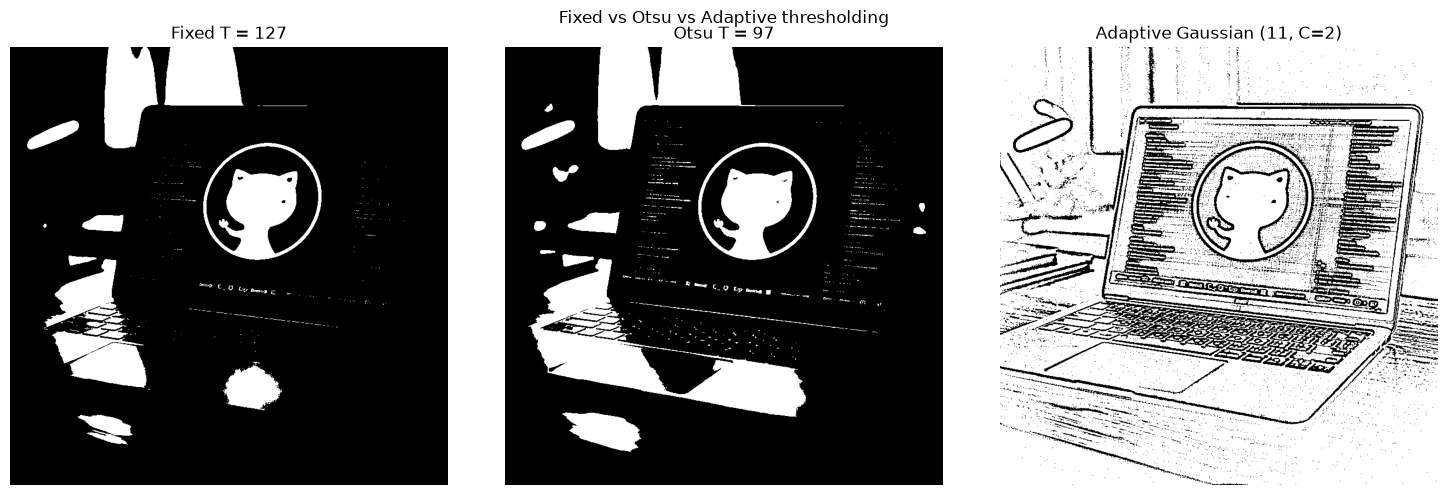

Unique values: [0, 255]
White pixels  fixed: 12.71%  otsu: 17.44%  adaptive: 82.58%


In [ ]:
adaptive = cv2.adaptiveThreshold(original, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY, 11, 2)
show_row([binary, otsu, adaptive], ["Fixed T = 127", f"Otsu T = {T_otsu:.0f}", "Adaptive Gaussian (11, C=2)"],
         "Fixed vs Otsu vs Adaptive thresholding")
print("Unique values:", np.unique(adaptive).tolist())
print("White pixels  fixed: %.2f%%  otsu: %.2f%%  adaptive: %.2f%%" %
      (100 * np.mean(binary == 255), 100 * np.mean(otsu == 255), 100 * np.mean(adaptive == 255)))

**Comparison:** *Complete for YOUR image.* Fixed and Otsu thresholds use one value for the whole image, so uneven lighting turns whole regions entirely white or black. Adaptive thresholding computes a local threshold for every pixel (Gaussian-weighted mean of its 11 × 11 neighbourhood minus C), so it keeps local edges and text in shadows, but it also amplifies noise in flat areas.

## Concept summary

- **Clipping:** values outside 0–255 are set to the nearest limit. It prevents wrap-around but merges distinct values, which permanently loses detail.
- **Overflow:** uint8 arithmetic wraps modulo 256 (240 + 40 = 24). Use int32/float64 for the arithmetic, clip, then convert to uint8.
- **Brightness vs contrast:** brightness adds a constant (shifts the histogram); contrast multiplies (spreads/compresses it). Centering the multiplication at 128 changes contrast without changing mid-gray.
- **Gamma convention:** here s = 255·(r/255)^γ, so γ < 1 brightens (expands darks) and γ > 1 darkens; 0 and 255 are fixed.
- **Global vs local:** global enhancement/thresholding is fast and fine for evenly lit images; local methods (CLAHE, adaptive threshold) help when illumination varies across the image.